In [1]:
# Initialize Otter
import otter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
grader = otter.Notebook("hwk2-task2-salmon-sloan.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

https://github.com/sacobjloan/eds220-hwk2


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

Text(0.5, 1.0, 'Average Catch by Region')

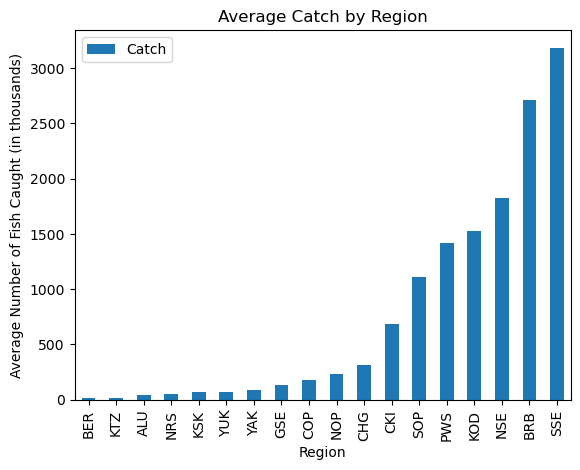

In [81]:
# FINAL CODE

catch_data = pd.read_csv('C:/Users/sacob/OneDrive/Desktop/MEDS current classes/EDS220_Environmental_Data_Science/eds220-hwk2/task2/data/salmon_data.csv')
catch_data = catch_data.drop(['notesRegCode'],axis = 1) # Dropping unneccesary columns
catch_data.loc[catch_data['Catch'] == 'I', 'Catch'] = 1 # Replaced accidental 'I' in count column with '1'
catch_data['Catch'] = catch_data['Catch'].astype('int64') # Converting 'Catch' column to int64 type
avg_region = catch_data.groupby('Region').mean('Catch') # Finding average catch by region
avg_region.sort_values(by = 'Catch').plot(y = 'Catch',kind = 'bar', use_index= True) 
plt.ylabel('Average Number of Fish Caught (in thousands)')
plt.title('Average Catch by Region')

## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [82]:
# a.


catch_data = pd.read_csv('C:/Users/sacob/OneDrive/Desktop/MEDS current classes/EDS220_Environmental_Data_Science/eds220-hwk2/task2/data/salmon_data.csv')


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [83]:
# b.

catch_data.info()
catch_data.value_counts()
catch_data.columns
catch_data.dtypes
catch_data.describe()
catch_data['Species'].unique() # Species only contains the 5 West Coast salmon species
catch_data.shape
catch_data['Year'].value_counts()

# Mostly qualitative data by year




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Region        8540 non-null   object
 1   Year          8540 non-null   int64 
 2   notesRegCode  1415 non-null   object
 3   Species       8540 non-null   object
 4   Catch         8540 non-null   object
dtypes: int64(1), object(4)
memory usage: 333.7+ KB


Year
1946    85
1955    85
1967    85
1966    85
1965    85
        ..
1882    10
1878     5
1879     5
1880     5
1881     5
Name: count, Length: 120, dtype: int64

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

Through the above exploration I learned what each column contains, how many rows and columns there are, and how long the data spanned. I've discovered that it's mostly characters in the df, other than the year column which is an integer.

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [84]:
notes_unique = catch_data['notesRegCode'].unique()
print(notes_unique)

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch' 'Estimated from canned production, probably sockeye'
 'No fishery' 'Bering River catches included in Copper River catches' 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches' 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned' 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned' 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned' 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks' 'Eshamy District only'
 'Estimated from canned; excludes Resurrection Bay' 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production' 'No reported catch'
 'Sockeye and pink and 9922 chum from Port Clarence area'

In [85]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [86]:
catch_data = catch_data.drop(['notesRegCode'],axis = 1)


In [87]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


No. The catch column, which is an integer, is a character string. Also, the year column is an integer and it's not a big deal, but it could be a date time.

In [88]:
catch_data.dtypes

Region     object
Year        int64
Species    object
Catch      object
dtype: object

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [89]:
catch_data['Catch'].astype('int64') # Throws an error because letters, such a 'I' can not be coerced to integer

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [90]:
catch_I = catch_data[catch_data['Catch'] == 'I'] # Finding rows where 'Catch' column = 'I'
catch_I 

,Region,Year,Species,Catch
400,GSE,1955,Chinook,I


In [91]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

In [92]:
catch_data.loc[catch_data['Catch'] == 'I', 'Catch'] = 1 

In [93]:


catch_1 = catch_data.iloc[400,] # Indexing row 400 of the df, where the was an 'I' instead of a 1


# Print catch_1
catch_1

Region         GSE
Year          1955
Species    Chinook
Catch            1
Name: 400, dtype: object

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [94]:
catch_data['Catch'] = catch_data['Catch'].astype('int64') # Setting type of 'Catch' column to int64
catch_column_type = catch_data['Catch'].dtype
catch_column_type

dtype('int64')

In [95]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [ ]:
avg_region = catch_data.groupby('Region').mean('Catch') # Grouping by region, then taking an average of catch
avg_region

,Year,Catch
Region,,
ALU,1954.0,40.383908
BER,1946.5,16.372549
BRB,1940.5,2709.796491
CHG,1942.5,315.487273
CKI,1945.0,683.571429
COP,1950.5,179.223404
GSE,1918.5,133.841463
KOD,1939.5,1528.350000
KSK,1955.0,67.642353


In [97]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

Text(0.5, 1.0, 'Average Catch by Region')

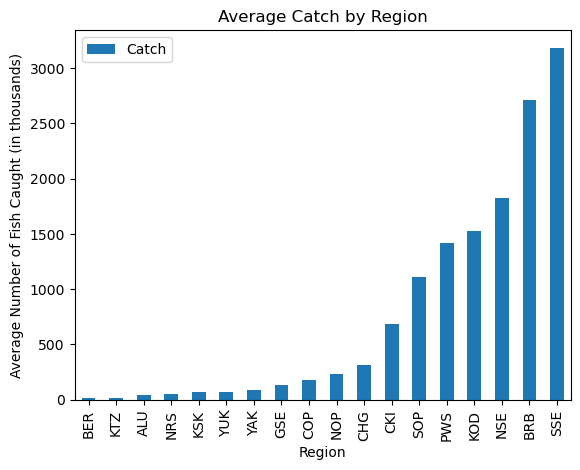

In [ ]:
avg_region.sort_values(by = 'Catch').plot(y = 'Catch',kind = 'bar', use_index= True) # Plotting the Catch column against the index (Region)
plt.ylabel('Average Number of Fish Caught (in thousands)')
plt.title('Average Catch by Region')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

The largest fisheries are the Southern Southeast Alaska fishery and the Bristol Bay Managment Area. The smallest fisheries are the Bering River Subarea Copper River Subarea and the Kotzebhue Manamgement Area.

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [99]:
grader.check_all()

q2a results: All test cases passed!

q2b results: All test cases passed!

q5 results: All test cases passed!

q7 results: All test cases passed!

q8 results: All test cases passed!